# Hillstrom Email Campaign: Predicting Customer Purchases

## 1. Project Overview
This notebook ranks customers by their likelihood of purchasing after an email campaign, using the Hillstrom MineThatData dataset (64,000 rows). It covers modeling and evaluation. Data cleaning and EDA are in separate notebooks, and the cleaned file is the input here.

To run it, use the `Notebooks` folder as the working directory; the data path is `../Data-raw/Cleaned/hillstrom_customers_cleaned.csv`.

## 2. Business Problem and Prediction Scenario
- The store can email only about 10,000 customers, roughly 17.4% of the eligible rows.
- **Decision to improve:** who should receive the email first.
- **Prediction scenario:** scoring happens *before* the campaign, so only information known at that time is allowed: `recency`, `history`, `mens`, `womens`, `newbie`, `zip_code`, `channel`.
- **Excluded columns:** `visit` and `spend` (post-campaign outcomes), `conversion` (the target), `segment` (campaign assignment) and `is_exact_repeat_after_first` (audit flag).
- **Scope of the claims:** this is predictive targeting. It says who is likely to buy, not who buys *because* of the email; that would require an uplift or A/B analysis.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    brier_score_loss,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

SEED = 42
os.makedirs("../figures", exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_colwidth", None)

## 3. Data Preparation and Train/Test Strategy
- Rows flagged as exact repeats are excluded (the assertion confirms no identical records remain, so no duplicate can sit on both sides of a split).
- Stratified split, because only about 1% of rows are buyers.
- An earlier exploratory notebook had already looked at a validation and test split. The final Test set is drawn only from rows that notebook never used for evaluation (its split is reproduced in the cell).
- Model tuning and selection use cross-validation on Train only. Test is used once, after the model and its settings are frozen.

In [ ]:
raw = pd.read_csv("../Data-raw/Cleaned/hillstrom_customers_cleaned.csv")

data = raw[raw["is_exact_repeat_after_first"] == 0]
assert not data.drop(columns="is_exact_repeat_after_first").duplicated().any()

features = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
X, y = data[features], data["conversion"]

rest, old_test = train_test_split(data.index, test_size=0.20, stratify=y, random_state=42)
old_train, old_val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=42)
_, test_idx = train_test_split(old_train, test_size=1 / 3, stratify=y.loc[old_train], random_state=123)
train_idx = data.index.difference(test_idx)

assert not set(train_idx) & set(test_idx)
assert not set(test_idx) & (set(old_val) | set(old_test))

X_train, y_train = X.loc[train_idx], y.loc[train_idx]
X_test, y_test = X.loc[test_idx], y.loc[test_idx]

capacity = 10_000 / len(data)
shares = [0.05, 0.10, capacity, 0.20, 0.30]
prevalence = y_train.mean()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
folds = list(cv.split(X_train, y_train))

pd.DataFrame(
    {"rows": [len(y_train), len(y_test)], "buyers": [y_train.sum(), y_test.sum()], "buyer rate": [y_train.mean(), y_test.mean()]},
    index=["Train", "Test"],
).round(4)

,rows,buyers,buyer rate
Train,45950,463,0.0101
Test,11488,115,0.0100


Train has 45,950 rows with 463 buyers (1.01%); Test has 11,488 rows with 115 buyers (1.00%). Both sets have the same buyer rate.

With a 1% buyer rate, predicting "no purchase" for everyone is about 99% accurate and finds no buyers, so Accuracy is not used. The main metric is **Average Precision (AP)**; a random ranking has AP equal to the buyer rate (about 0.010).

## 4. Feature Engineering and Pipeline
- `recency`: scaled.
- `history`: right-skewed, so `log1p` then scaling.
- `mens`, `womens`, `newbie`: binary, used as they are.
- `zip_code`, `channel`: One-Hot encoded (`handle_unknown="ignore"`).
- `history_segment` is dropped: it is only a binned copy of `history`.

All preprocessing sits inside one Pipeline, so it is fitted only on the training part of each fold. No oversampling or SMOTE is used. The helper functions below rank customers (random tie-breaking) and compute top-k, Lift and gain.

In [3]:
def build_pipeline(model, category_columns=["zip_code", "channel"]):
    prep = ColumnTransformer(
        [
            (
                "history",
                Pipeline([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")), ("scale", StandardScaler())]),
                ["history"],
            ),
            ("recency", StandardScaler(), ["recency"]),
            ("category", OneHotEncoder(handle_unknown="ignore"), category_columns),
        ],
        remainder="passthrough",
        sparse_threshold=0,
    )
    return Pipeline([("prep", prep), ("model", model)])


def rank_order(score):
    # Indices from highest to lowest score; ties are broken at random (fixed seed).
    tie_break = np.random.default_rng(SEED).random(len(score))
    return np.lexsort((tie_break, -np.asarray(score)))


def topk_table(y_true, score, shares):
    y_true = np.asarray(y_true)
    order = rank_order(score)
    rows = []
    for share in shares:
        k = int(np.ceil(len(y_true) * share))
        buyers = y_true[order[:k]].sum()
        precision, recall = buyers / k, buyers / y_true.sum()
        rows.append(
            {
                "share": share,
                "selected": k,
                "buyers": buyers,
                "precision": precision,
                "recall": recall,
                "f1": 2 * precision * recall / (precision + recall) if buyers else 0.0,
                "lift": precision / y_true.mean(),
            }
        )
    return pd.DataFrame(rows)


def gain_curve(y_true, score, grid=np.linspace(0, 1, 101)):
    y_true = np.asarray(y_true)
    cumulative = np.concatenate([[0], np.cumsum(y_true[rank_order(score)])]) / y_true.sum()
    return np.interp(grid, np.arange(len(cumulative)) / len(y_true), cumulative)

## 5. Data Leakage Check
The same Logistic Regression is cross-validated on three feature sets: A (pre-campaign features), B (A + `visit`) and C (A + `spend`).

In [4]:
leakage_sets = {
    "A: pre-campaign features": features,
    "B: A + visit": features + ["visit"],
    "C: A + spend": features + ["spend"],
}

leakage = {}
for name, columns in leakage_sets.items():
    result = cross_validate(
        build_pipeline(LogisticRegression(max_iter=5000)),
        data.loc[X_train.index, columns],
        y_train,
        cv=cv,
        scoring=["roc_auc", "average_precision"],
    )
    leakage[name] = {"ROC-AUC": result["test_roc_auc"].mean(), "AP": result["test_average_precision"].mean()}

pd.DataFrame(leakage).T.round(4)

,ROC-AUC,AP
A: pre-campaign features,0.5853,0.0144
B: A + visit,0.9287,0.0746
C: A + spend,1.0000,1.0000


Adding `visit` lifts AUC from 0.585 to 0.929, and adding `spend` gives a perfect 1.0, because `spend > 0` is exactly the target. This information does not exist before the campaign, so B and C are shown only to illustrate leakage. All later models use feature set A.

## 6. Baseline and Candidate Models
- **Dummy** (buyer rate only) and a default **Logistic Regression** are the references.
- Candidates: Logistic Regression, Decision Tree, Random Forest and XGBoost, each with a small grid.
- **Nested CV:** hyperparameters are chosen by AP in an inner 3-fold CV on each outer training part; the outer 5-fold validation parts then give a less optimistic estimate. Every number below comes from folds the tuned model never saw.
- Ranking metrics (top-k, gain) are computed inside each validation fold and averaged, so scores from differently tuned fold models are never pooled.

In [ ]:
models = {
    "Logistic regression": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.1, 1, 10], "model__class_weight": [None, "balanced"]},
    ),
    "Decision tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [50, 100, 200]},
    ),
    "Random forest": (
        RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=SEED),
        {"model__max_depth": [4, 8], "model__min_samples_leaf": [30, 100]},
    ),
    "XGBoost": (
        XGBClassifier(n_estimators=100, eval_metric="logloss", n_jobs=-1, random_state=SEED),
        {"model__max_depth": [2, 3], "model__learning_rate": [0.03, 0.1]},
    ),
}
references = {
    "Dummy": (DummyClassifier(strategy="prior"), {}),
    "Baseline logistic": (LogisticRegression(max_iter=2000), {}),
}

cv_rows, topk_cv, gain_cv, fold_params = [], {}, {}, {}
for name, (model, grid) in {**references, **models}.items():
    scores = {"AP": [], "ROC-AUC": [], "Brier": []}
    topk, gain, params = [], [], []
    for train_part, valid_part in folds:
        pipeline = build_pipeline(model)
        if grid:
            pipeline = GridSearchCV(pipeline, grid, scoring="average_precision", cv=inner_cv)
        pipeline.fit(X_train.iloc[train_part], y_train.iloc[train_part])
        y_valid, score = y_train.iloc[valid_part], pipeline.predict_proba(X_train.iloc[valid_part])[:, 1]
        scores["AP"].append(average_precision_score(y_valid, score))
        scores["ROC-AUC"].append(roc_auc_score(y_valid, score))
        scores["Brier"].append(brier_score_loss(y_valid, score))
        topk.append(topk_table(y_valid, score, shares))
        gain.append(gain_curve(y_valid, score))
        if grid:
            params.append(str(pipeline.best_params_))
    row = {"Model": name}
    for metric, values in scores.items():
        row[f"{metric} mean"], row[f"{metric} std"] = np.mean(values), np.std(values)
    row["Most chosen params"] = pd.Series(params).mode()[0] if params else "default"
    cv_rows.append(row)
    topk_cv[name] = pd.concat(topk).groupby("share").mean()
    gain_cv[name] = np.mean(gain, axis=0)
    fold_params[name] = params

cv_summary = pd.DataFrame(cv_rows).set_index("Model")
best_name = cv_summary.loc[list(models), "AP mean"].idxmax()
cv_summary.drop(columns="Most chosen params").round(4)

,AP mean,AP std,ROC-AUC mean,ROC-AUC std,Brier mean,Brier std
Model,,,,,,
Dummy,0.0101,0.0001,0.5000,0.0000,0.0100,0.0001
Baseline logistic,0.0144,0.0013,0.5853,0.0224,0.0100,0.0000
Logistic regression,0.0142,0.0013,0.5847,0.0216,0.0567,0.0935
Decision tree,0.0136,0.0012,0.5790,0.0135,0.0100,0.0001
Random forest,0.0207,0.0035,0.6247,0.0274,0.0100,0.0001
XGBoost,0.0176,0.0021,0.6090,0.0242,0.0100,0.0001


## 7. Cross-Validation Results and Model Selection
Random Forest has the highest mean AP (0.0207 ± 0.0035), ahead of XGBoost (0.0187 ± 0.0032). Logistic Regression (0.0142), the Decision Tree (0.0136) and the default baseline (0.0144) are only slightly above Dummy (0.0101). AUC follows the same order (Random Forest 0.625, XGBoost 0.616, the rest about 0.58).

The gap between Random Forest and XGBoost (0.002) is smaller than the fold-to-fold spread, so the two are not clearly different. Random Forest is selected because it has the highest mean AP, not because it is proven better. Tuning did not help Logistic Regression.

The tuned Logistic Regression has a large Brier standard deviation most likely because some folds selected `class_weight="balanced"`, which inflates its scores.

In [6]:
cv_summary[["Most chosen params"]]

,Most chosen params
Model,
Dummy,default
Baseline logistic,default
Logistic regression,"{'model__C': 0.1, 'model__class_weight': None}"
Decision tree,"{'model__max_depth': 5, 'model__min_samples_leaf': 100}"
Random forest,"{'model__max_depth': 4, 'model__min_samples_leaf': 100}"
XGBoost,"{'model__learning_rate': 0.03, 'model__max_depth': 3}"


The hyperparameters chosen most often across the outer folds are shown above. The grids are small on purpose: with about 90 buyers per validation fold, a larger search would mostly fit noise.

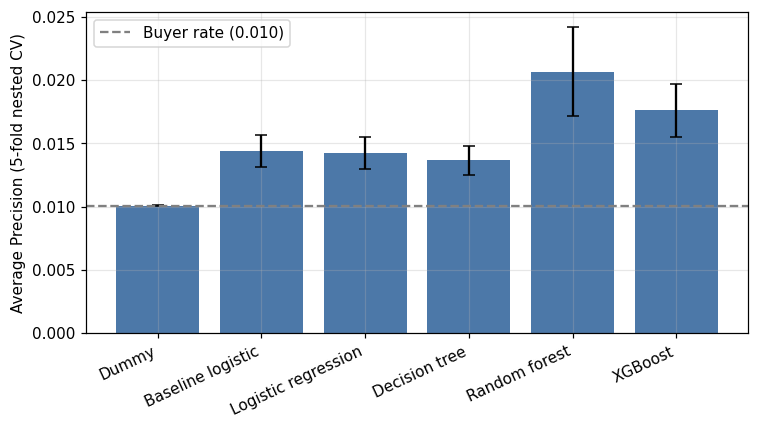

In [7]:
plot_data = cv_summary
plt.figure(figsize=(7, 4))
plt.bar(plot_data.index, plot_data["AP mean"], yerr=plot_data["AP std"], capsize=4, color="#4c78a8")
plt.axhline(prevalence, color="gray", linestyle="--", label=f"Buyer rate ({prevalence:.3f})")
plt.ylabel("Average Precision (5-fold nested CV)")
plt.xticks(rotation=25, ha="right")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/cv_average_precision.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** AP per model with the fold standard deviation. **Meaning:** the tree ensembles are the only models clearly above the baseline, and their error bars still overlap each other. **Why it matters:** the signal is weak, and the choice between Random Forest and XGBoost should not be oversold.

In [8]:
pd.concat(topk_cv, names=["model"])[["selected", "buyers", "precision", "recall", "lift"]].loc[list(models)].round(3)

selected  buyers  precision  recall   lift
model               share                                               
Logistic regression 0.050000     460.0     8.2      0.018   0.088  1.767
                    0.100000     919.0    14.8      0.016   0.160  1.597
                    0.174101    1600.0    25.2      0.016   0.272  1.563
                    0.200000    1838.0    27.4      0.015   0.296  1.479
                    0.300000    2757.0    39.6      0.014   0.428  1.426
Decision tree       0.050000     460.0     7.8      0.017   0.084  1.684
                    0.100000     919.0    13.6      0.015   0.147  1.469
                    0.174101    1600.0    22.2      0.014   0.240  1.377
                    0.200000    1838.0    24.4      0.013   0.263  1.317
                    0.300000    2757.0    39.0      0.014   0.421  1.404
Random forest       0.050000     460.0    11.2      0.024   0.121  2.416
                    0.100000     919.0    19.0      0.021   0.205  2.051
                    0.174101    1600.0    27.6      0.017   0.298  1.711
                    0.200000    1838.0    31.8      0.017   0.343  1.716
                    0.300000    2757.0    43.4      0.016   0.469  1.562
XGBoost             0.050000     460.0    10.4      0.023   0.112  2.243
                    0.100000     919.0    17.6      0.019   0.190  1.900
                    0.174101    1600.0    26.6      0.017   0.287  1.650
                    0.200000    1838.0    29.2      0.016   0.315  1.577
                    0.300000    2757.0    41.4      0.015   0.447  1.490

This is the capacity view inside the validation folds (about 9,190 customers each). At the campaign share (17.4%, about 1,600 customers per fold) Random Forest finds about 28 buyers, with precision 0.017, recall 0.298 and Lift 1.71. XGBoost has Lift 1.61, Logistic 1.56 and the Decision Tree 1.38. At 5% Random Forest reaches Lift 2.42. All models beat random targeting (Lift 1), and Lift falls as the contacted share grows.

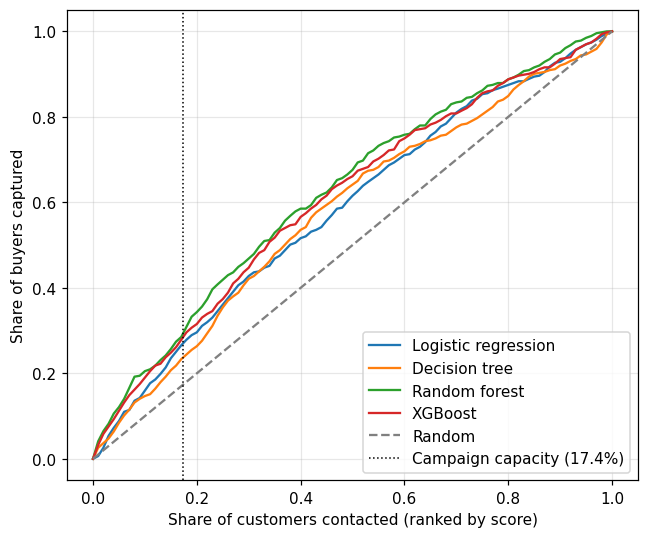

In [9]:
grid_points = np.linspace(0, 1, 101)
plt.figure(figsize=(6, 5))
for name in models:
    plt.plot(grid_points, gain_cv[name], label=name)
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")
plt.axvline(capacity, color="black", linestyle=":", linewidth=1, label=f"Campaign capacity ({capacity:.1%})")
plt.xlabel("Share of customers contacted (ranked by score)")
plt.ylabel("Share of buyers captured")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/cv_cumulative_gain.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** the share of buyers captured as more customers are contacted, averaged over validation folds. **Meaning:** every model sits above the random diagonal, with Random Forest slightly ahead near the campaign capacity (dotted line). **Why it matters:** contacting the top 17.4% captures roughly 24% to 30% of buyers, not the roughly 17% a random list would give.

## 8. Final Model and Calibration
The selected configuration is refitted on the full training set. Calibration is checked on out-of-fold training scores of this single configuration, so Test is not involved.

In [10]:
model, grid = models[best_name]
final_search = GridSearchCV(build_pipeline(model), grid, scoring="average_precision", cv=inner_cv)
final_search.fit(X_train, y_train)
final_model = final_search.best_estimator_

# Out-of-fold scores of this single configuration (same hyperparameters in every fold).
oof_pipeline = build_pipeline(clone(model).set_params(**{k.split("__")[1]: v for k, v in final_search.best_params_.items()}))
oof_score = np.empty(len(y_train))
for train_part, valid_part in folds:
    fitted = clone(oof_pipeline).fit(X_train.iloc[train_part], y_train.iloc[train_part])
    oof_score[valid_part] = fitted.predict_proba(X_train.iloc[valid_part])[:, 1]

pd.Series(final_search.best_params_, name=best_name).to_frame()

,Random forest
model__max_depth,4
model__min_samples_leaf,30


Final configuration: Random Forest with `max_depth=4` and `min_samples_leaf=30`.

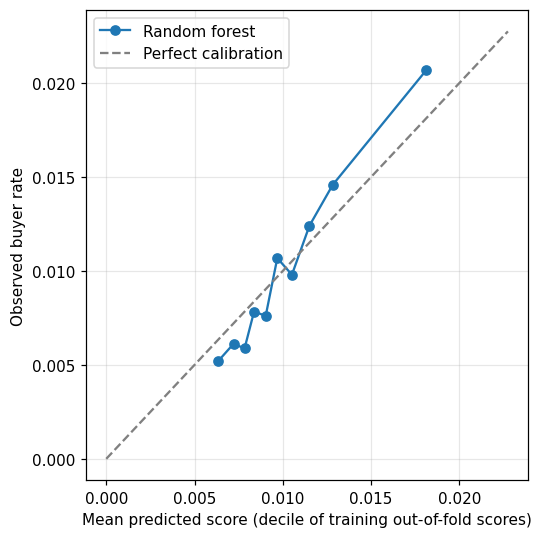

,value
"Brier score (model, OOF)",0.0100
Brier score (constant buyer rate),0.0100
Max OOF score,0.0496


In [11]:
prob_true, prob_pred = calibration_curve(y_train, oof_score, n_bins=10, strategy="quantile")
plt.figure(figsize=(5, 5))
plt.plot(prob_pred, prob_true, marker="o", label=best_name)
upper = max(prob_pred.max(), prob_true.max()) * 1.1
plt.plot([0, upper], [0, upper], "--", color="gray", label="Perfect calibration")
plt.xlabel("Mean predicted score (decile of training out-of-fold scores)")
plt.ylabel("Observed buyer rate")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/calibration_oof.png", dpi=150, bbox_inches="tight")
plt.show()

pd.Series(
    {
        "Brier score (model, OOF)": brier_score_loss(y_train, oof_score),
        "Brier score (constant buyer rate)": brier_score_loss(y_train, np.full(len(y_train), prevalence)),
        "Max OOF score": oof_score.max(),
    }
).round(4).to_frame("value")

**What it shows:** observed buyer rate against the mean predicted score in score deciles. **Meaning:** the scores stay in a narrow range (maximum 0.05) and follow the diagonal reasonably, with the top decile slightly under-predicted. The Brier score equals that of a constant buyer rate (0.0100), so the model adds ranking information but not sharper probabilities. **Why it matters:** use the scores to rank customers, and do not read them as exact purchase probabilities.

## 9. Final Test Evaluation
The Test set is scored once with the frozen model. Capacity-based results use the exact top-k customers by rank, with no probability threshold.

In [12]:
test_score = final_model.predict_proba(X_test)[:, 1]

pd.Series(
    {
        "ROC-AUC": roc_auc_score(y_test, test_score),
        "Average Precision": average_precision_score(y_test, test_score),
        "Buyer rate (AP baseline)": y_test.mean(),
        "Brier score": brier_score_loss(y_test, test_score),
    }
).round(4).to_frame(best_name)

,Random forest
ROC-AUC,0.6517
Average Precision,0.0303
Buyer rate (AP baseline),0.0100
Brier score,0.0099


On Test the model reaches ROC-AUC 0.652 and AP 0.030, about three times the buyer rate of 0.010. These cannot be compared directly with the cross-validation numbers (different data and procedure); the higher Test value is within the noise expected from only 115 buyers.

In [13]:
# Exact top-k selection on the held-out Test set (ranking only, no probability threshold).
test_topk = topk_table(y_test, test_score, shares)
test_topk.round(3)

,share,selected,buyers,precision,recall,f1,lift
0,0.050,575,22,0.038,0.191,0.064,3.822
1,0.100,1149,30,0.026,0.261,0.047,2.608
2,0.174,2001,43,0.021,0.374,0.041,2.147
3,0.200,2298,48,0.021,0.417,0.040,2.087
4,0.300,3447,60,0.017,0.522,0.034,1.739


Contacting the top 17.4% of Test customers (2,001 people) reaches 43 of 115 buyers: recall 0.374, precision 0.021 and Lift 2.15. The top 5% (575 people) contains 22 buyers (Lift 3.8). Precision stays low in absolute terms because buyers are rare. With 115 buyers, each of these Lift values has wide uncertainty.

## 10. Threshold and Capacity Analysis
A fixed probability threshold and a fixed share of customers are different ways to choose a campaign list. Thresholds below come from out-of-fold training scores only and are then applied to Test.

In [14]:
# Probability thresholds are taken from training out-of-fold scores only.
rows = []
for label, threshold in [(f"fixed {t}", t) for t in [0.3, 0.4, 0.5, 0.6, 0.7]] + [
    (f"OOF top {s:.1%}", np.quantile(oof_score, 1 - s)) for s in shares
]:
    chosen = test_score >= threshold
    buyers = y_test[chosen].sum()
    rows.append(
        {
            "rule": label,
            "threshold": threshold,
            "OOF share selected": (oof_score >= threshold).mean(),
            "Test share selected": chosen.mean(),
            "Test precision": buyers / chosen.sum() if chosen.any() else 0.0,
            "Test recall": buyers / y_test.sum(),
        }
    )

pd.DataFrame(rows).set_index("rule").round(4)

,threshold,OOF share selected,Test share selected,Test precision,Test recall
rule,,,,,
fixed 0.3,0.3000,0.0000,0.0000,0.0000,0.0000
fixed 0.4,0.4000,0.0000,0.0000,0.0000,0.0000
fixed 0.5,0.5000,0.0000,0.0000,0.0000,0.0000
fixed 0.6,0.6000,0.0000,0.0000,0.0000,0.0000
fixed 0.7,0.7000,0.0000,0.0000,0.0000,0.0000
OOF top 5.0%,0.0158,0.0500,0.0467,0.0410,0.1913
OOF top 10.0%,0.0138,0.1000,0.0828,0.0273,0.2261
OOF top 17.4%,0.0124,0.1741,0.1495,0.0210,0.3130
OOF top 20.0%,0.0121,0.2000,0.1731,0.0216,0.3739


Thresholds of 0.3 to 0.7 select nobody, because the model's scores never exceed about 0.05; such cut-offs are meaningless for this model. A threshold that selects 17.4% of the training out-of-fold scores (0.0124) selects only 15.0% of Test customers, so a threshold does not reproduce a campaign size. Since the business has a fixed capacity, the list should be built by ranking and taking the top k.

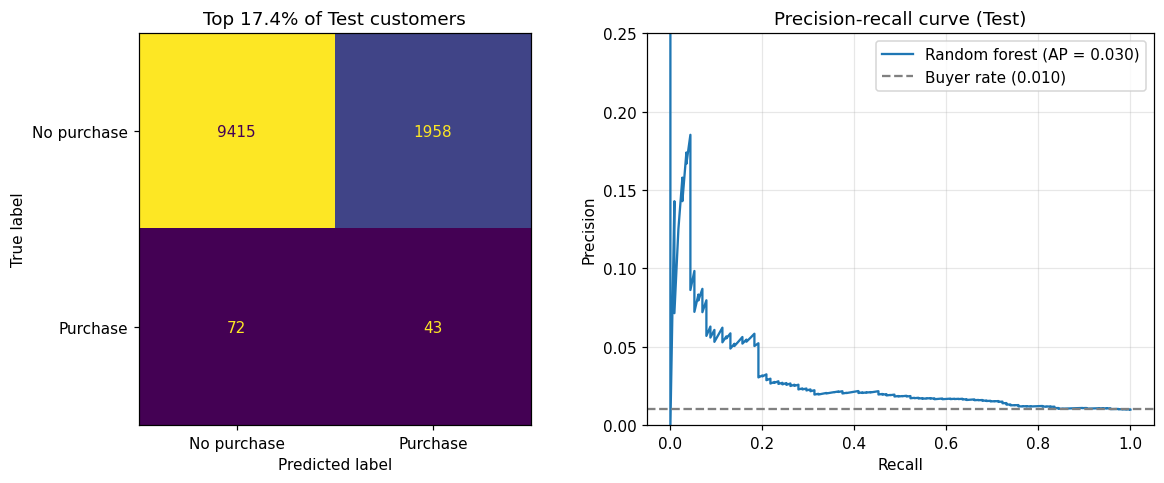

In [15]:
k = int(np.ceil(len(y_test) * capacity))
selected = np.zeros(len(y_test), dtype=bool)
selected[rank_order(test_score)[:k]] = True

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, selected, ax=axes[0], colorbar=False, values_format="d", display_labels=["No purchase", "Purchase"]
)
axes[0].set_title(f"Top {capacity:.1%} of Test customers")
axes[0].grid(False)

precision, recall, _ = precision_recall_curve(y_test, test_score)
axes[1].plot(recall, precision, label=f"{best_name} (AP = {average_precision_score(y_test, test_score):.3f})")
axes[1].axhline(y_test.mean(), color="gray", linestyle="--", label=f"Buyer rate ({y_test.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (Test)", ylim=(0, 0.25))
axes[1].legend()

plt.tight_layout()
plt.savefig("../figures/test_confusion_pr.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** the confusion matrix for the top 17.4% of Test (43 buyers found, 72 missed, 1,958 non-buyers contacted) and the precision-recall curve (y-axis limited to 0.25 for readability). **Meaning:** about 98% of contacted customers do not buy, yet precision is above the 1% buyer rate at almost all recall levels. **Why it matters:** a missed buyer is lost revenue and a contacted non-buyer costs an email slot; their relative cost depends on email cost and margin, which are not in the data.

## 11. Business Rule Comparison
Simple rule: customers who bought in the last 3 months (`recency <= 3`) and have high past spend (`history` at or above the 75th percentile of Train). The cut-off comes from training data only and nothing is tuned on Test. Rule scores take three values, so ties are broken at random.

In [16]:
# Business rule: recent buyers (last 3 months) with high past spend.
# The spend cut-off is the 75th percentile of Train history; nothing is tuned on Test.
history_cut = X_train["history"].quantile(0.75)
rule_test = (X_test["recency"] <= 3).astype(int) + (X_test["history"] >= history_cut).astype(int)

rule_topk = topk_table(y_test, rule_test, shares)
comparison = pd.DataFrame(
    {
        "selected": test_topk["selected"].to_numpy(),
        "model buyers": test_topk["buyers"].to_numpy(),
        "rule buyers": rule_topk["buyers"].to_numpy(),
        "model lift": test_topk["lift"].to_numpy(),
        "rule lift": rule_topk["lift"].to_numpy(),
        "model recall": test_topk["recall"].to_numpy(),
        "rule recall": rule_topk["recall"].to_numpy(),
    },
    index=[f"{s:.1%}" for s in shares],
).round(3)
comparison

,selected,model buyers,rule buyers,model lift,rule lift,model recall,rule recall
5.0%,575,22,11,3.822,1.911,0.191,0.096
10.0%,1149,30,19,2.608,1.652,0.261,0.165
17.4%,2001,43,32,2.147,1.598,0.374,0.278
20.0%,2298,48,37,2.087,1.608,0.417,0.322
30.0%,3447,60,48,1.739,1.391,0.522,0.417


At every campaign size the model finds more buyers than the rule: 43 against 32 at 17.4%, and Lift 2.15 against 1.60. The advantage is largest at small shares (22 against 11 buyers in the top 5%). The rule already captures part of the signal, but the model adds value on top of it.

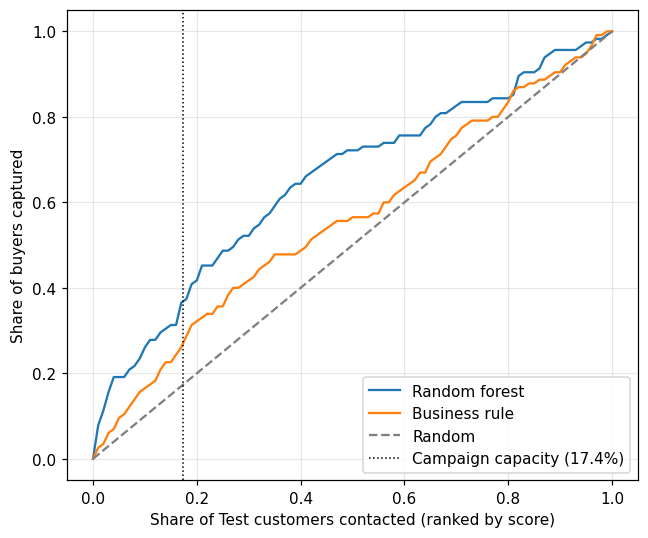

In [17]:
plt.figure(figsize=(6, 5))
plt.plot(grid_points, gain_curve(y_test, test_score), label=best_name)
plt.plot(grid_points, gain_curve(y_test, rule_test), label="Business rule")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random")
plt.axvline(capacity, color="black", linestyle=":", linewidth=1, label=f"Campaign capacity ({capacity:.1%})")
plt.xlabel("Share of Test customers contacted (ranked by score)")
plt.ylabel("Share of buyers captured")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/test_cumulative_gain.png", dpi=150, bbox_inches="tight")
plt.show()

**What it shows:** gain curves on Test for the model and the rule. **Meaning:** the model is above the rule for most of the range and both beat random. **Why it matters:** with 115 buyers the gap is suggestive rather than precise, but it supports using the model for ranking.

## 12. Customer Targeting (Illustrative)
The held-out rows are ranked with one fitted model, so all scores come from the same procedure. The dataset has no customer ID, so rows are identified only by their row index in the cleaned CSV. This is an illustration, not a deployable contact list; a real campaign would refit on all labelled data and score the actual customer base.

In [18]:
# Illustrative ranking of the held-out rows with one fitted model (one consistent score).
# The data has no customer ID: rows are identified only by their row index in the cleaned CSV.
order = rank_order(test_score)[:k]
campaign_list = X_test.iloc[order].assign(score=test_score[order])
campaign_list.index.name = "row_index"
campaign_list.head(10)

,recency,history,mens,womens,newbie,zip_code,channel,score
row_index,,,,,,,,
41363,12,29.99,1,0,0,Urban,Web,0.042819
42592,12,29.99,0,1,0,Urban,Web,0.041527
8621,12,29.99,0,1,0,Urban,Web,0.041527
39940,12,29.99,1,0,1,Urban,Web,0.041205
56631,12,29.99,0,1,1,Urban,Web,0.040733
39341,3,29.99,0,1,0,Urban,Web,0.037559
12902,3,29.99,0,1,0,Urban,Web,0.037559
12607,4,29.99,0,1,0,Urban,Web,0.037367
1995,2,29.99,0,1,0,Urban,Web,0.037138


The list contains the top 17.4% of Test rows (2,001). The highest scores share a pattern: the lowest `history` value (29.99), Urban and Web. The next table checks it on Train.

In [19]:
# What do the highest scores have in common? Buyer rate by segment on Train only.
low_history = X_train["history"] == X_train["history"].min()
urban_web = (X_train["zip_code"] == "Urban") & (X_train["channel"] == "Web")
segment_name = np.select(
    [low_history & urban_web, low_history],
    ["lowest history, Urban, Web", "lowest history, other"],
    default="all other customers",
)
pd.DataFrame({"buyer": y_train.to_numpy(), "segment": segment_name}).groupby("segment")["buyer"].agg(
    customers="size", buyers="sum", buyer_rate="mean"
).round(4)

,customers,buyers,buyer_rate
segment,,,
all other customers,44812,424,0.0095
"lowest history, Urban, Web",202,13,0.0644
"lowest history, other",936,26,0.0278


On Train, customers with the lowest `history` who are Urban and on the Web channel buy at 6.4% (13 of 202), against 0.95% for everyone else; other lowest-`history` customers buy at 2.8% (26 of 936). The model is therefore concentrating on a small, genuinely higher-converting pocket, but it rests on only 13 buyers and should be treated as a hypothesis to confirm, not a rule.

## 13. Model Explainability
- **Permutation Importance** applies to the selected Random Forest. It is computed on validation folds of Train (not Test) as the drop in AP when a feature is shuffled.
- **Logistic Regression coefficients** are a separate interpretation of the Logistic model. They do not explain the Random Forest.
- Both describe associations in the data, not causes.

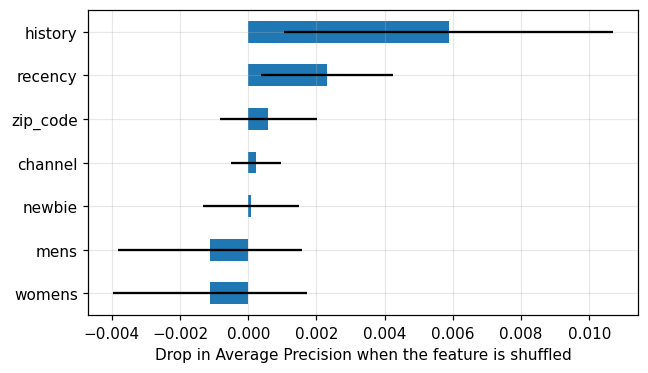

,mean,std
womens,-0.0011,0.0028
mens,-0.0011,0.0027
newbie,0.0001,0.0014
channel,0.0002,0.0007
zip_code,0.0006,0.0014
recency,0.0023,0.0019
history,0.0059,0.0048


In [20]:
# Permutation importance on validation folds of Train, with the selected configuration.
importance_rows = []
for train_part, valid_part in folds:
    fitted = clone(oof_pipeline).fit(X_train.iloc[train_part], y_train.iloc[train_part])
    result = permutation_importance(
        fitted, X_train.iloc[valid_part], y_train.iloc[valid_part],
        scoring="average_precision", n_repeats=5, random_state=SEED,
    )
    importance_rows.append(result.importances_mean)

importance = pd.DataFrame(importance_rows, columns=X_train.columns).agg(["mean", "std"]).T.sort_values("mean")

importance["mean"].plot.barh(xerr=importance["std"], figsize=(6, 3.5))
plt.xlabel("Drop in Average Precision when the feature is shuffled")
plt.tight_layout()
plt.savefig("../figures/permutation_importance.png", dpi=150, bbox_inches="tight")
plt.show()

importance.round(4)

`history` has the largest mean drop in AP (0.0059) and `recency` is next (0.0023), but both are about one standard deviation or less. The other features are close to zero. With 463 training buyers, feature importance cannot be ranked reliably; the finding is that `history` and `recency` carry most of whatever signal there is.

In [21]:
# Logistic regression interpretation only (not an explanation of the selected model).
logit_model, logit_grid = models["Logistic regression"]
logit_search = GridSearchCV(build_pipeline(logit_model), logit_grid, scoring="average_precision", cv=inner_cv)
logit_search.fit(X_train, y_train)
logit = logit_search.best_estimator_

feature_names = logit.named_steps["prep"].get_feature_names_out()
coefficients = pd.Series(logit.named_steps["model"].coef_[0], index=feature_names).sort_values()
pd.DataFrame({"coefficient": coefficients, "odds_ratio": np.exp(coefficients)}).round(3)

,coefficient,odds_ratio
remainder__newbie,-0.267,0.766
category__channel_Phone,-0.248,0.780
recency__recency,-0.207,0.813
category__zip_code_Suburban,-0.169,0.845
category__zip_code_Urban,-0.085,0.919
category__channel_Web,-0.032,0.969
category__zip_code_Rural,0.005,1.005
history__history,0.020,1.020
category__channel_Multichannel,0.032,1.032
remainder__mens,0.430,1.537


In the Logistic model (scaled numeric features, raw binaries), a `womens` purchase history (odds ratio 1.75) and a `mens` history (1.54) go with higher purchase odds; `newbie` (0.77), the Phone channel (0.78) and Suburban zip codes (0.85) go with lower odds; a more recent last purchase (`recency`, 0.81 per standard deviation) goes with higher odds; the linear effect of `history` is negligible. Random Forest ranks `history` first, which suggests a non-linear effect that Logistic Regression cannot capture.

## 14. Explaining Individual Customers
Logistic Regression only: three Test customers with the highest, median and lowest logistic score. The scores come from the Logistic model and are not those of the selected model.

In [22]:
# Logistic regression only: three Test customers (highest, median and lowest score).
logit_score = logit.predict_proba(X_test)[:, 1]
picked = [logit_score.argmax(), np.argsort(logit_score)[len(logit_score) // 2], logit_score.argmin()]
labels = ["High", "Medium", "Low"]

contributions = pd.DataFrame(
    logit.named_steps["prep"].transform(X_test.iloc[picked]) * coefficients.reindex(feature_names).values,
    index=labels,
    columns=feature_names,
).T.round(3)
customers = X_test.iloc[picked].assign(logistic_score=logit_score[picked]).set_axis(labels)
customers

,recency,history,mens,womens,newbie,zip_code,channel,logistic_score
High,1,472.74,1,1,0,Rural,Multichannel,0.745546
Medium,10,330.61,0,1,0,Suburban,Multichannel,0.482669
Low,12,29.99,1,0,1,Suburban,Phone,0.285788


In [23]:
contributions

,High,Medium,Low
history__history,0.021,0.013,-0.038
recency__recency,0.276,-0.257,-0.375
category__zip_code_Rural,0.005,0.000,0.000
category__zip_code_Suburban,-0.000,-0.169,-0.169
category__zip_code_Urban,-0.000,-0.000,-0.000
category__channel_Multichannel,0.032,0.032,0.000
category__channel_Phone,-0.000,-0.000,-0.248
category__channel_Web,-0.000,-0.000,-0.000
remainder__mens,0.430,0.000,0.430
remainder__womens,0.560,0.560,0.000


The highest-scored customer is recent (`recency` 1) and has both `mens` and `womens` history; the lowest-scored one last bought 12 months ago, is new, uses the Phone channel and lives in a Suburban area. The contributions are on the log-odds scale and describe associations in this model only.

## 15. Customer Value and Purchase Score
Value is `history` above the Train median; a high score means the top 20% of Test scores from the selected model.

In [24]:
segments = X_test[["history"]].assign(bought=y_test, score=test_score)
high_value = segments["history"] >= X_train["history"].median()
high_score = segments["score"] >= np.quantile(segments["score"], 0.80)

segments["group"] = np.select(
    [high_value & high_score, high_value & ~high_score, ~high_value & high_score],
    ["Priority", "Retention", "Growth"],
    default="Low priority",
)
segments.groupby("group").agg(
    customers=("bought", "size"), buyers=("bought", "sum"), conversion_rate=("bought", "mean"), avg_history=("history", "mean")
).round(3)

,customers,buyers,conversion_rate,avg_history
group,,,,
Growth,622,17,0.027,67.705
Low priority,5213,38,0.007,98.113
Priority,1681,31,0.018,639.086
Retention,3972,29,0.007,361.406


- **Priority** (high value, high score): 1,681 customers, 31 buyers (1.8%). Contact first.
- **Growth** (low value, high score): 622 customers, 17 buyers (2.7%). Low-cost offers that raise customer value.
- **Retention** (high value, low score): 3,972 customers, 29 buyers (0.7%). Keep in touch cheaply; do not spend heavily.
- **Low priority:** 5,213 customers, 38 buyers (0.7%). Skip, or run only a small test.

Counts are small (17 to 38 buyers per group), so the differences between groups are indicative only.

## 16. Adding `segment` (Diagnostic)
`segment` is the randomly assigned campaign group, so it is not available as a pre-campaign feature. It is added to a Logistic Regression only to see how much it changes cross-validated performance.

In [25]:
segment_check = {}
for name, columns, categories in [
    ("Without segment", features, ["zip_code", "channel"]),
    ("With segment", features + ["segment"], ["zip_code", "channel", "segment"]),
]:
    result = cross_validate(
        build_pipeline(LogisticRegression(max_iter=2000), categories),
        data.loc[X_train.index, columns],
        y_train,
        cv=cv,
        scoring=["roc_auc", "average_precision"],
    )
    segment_check[name] = {
        "ROC-AUC mean": result["test_roc_auc"].mean(), "ROC-AUC std": result["test_roc_auc"].std(),
        "AP mean": result["test_average_precision"].mean(), "AP std": result["test_average_precision"].std(),
    }

pd.DataFrame(segment_check).T.round(4)

,ROC-AUC mean,ROC-AUC std,AP mean,AP std
Without segment,0.5853,0.0224,0.0144,0.0013
With segment,0.6137,0.0231,0.0171,0.0026


AUC rises from 0.585 to 0.614 and AP from 0.0144 to 0.0171, a gain of about one standard deviation. This only shows an association between the campaign group and purchasing in this data. It is not an estimate of the campaign's causal effect, and `segment` stays out of the operational model.

## 17. Business Recommendations
- Use the model to **rank** customers and contact the top of the list first; a 10,000-customer campaign is about the top 17.4% of the base.
- Expect a moderate gain, not a precise forecast: Lift is about 1.6 to 2.1 at that size, and recall about 0.28 to 0.37.
- Prefer a fixed top-k list over a probability threshold, and do not present the scores as purchase probabilities.
- Confirm the low-`history`, Urban, Web pocket with new data before acting on it.
- Measure the true campaign effect with an A/B test or uplift model.

## 18. Limitations
- No customer ID: rows are records, not verified unique customers, so the output is not a deployable contact list.
- Few buyers (463 in Train, 115 in Test): all estimates are noisy and Lift values carry wide uncertainty.
- Removing exact repeats raises the buyer rate (from about 0.90% to 1.01%) because all removed rows were non-buyers.
- The Test set avoids rows used in an earlier exploratory evaluation, but it comes from the same dataset and period, so it is not independent in a strict sense.
- Random Forest and XGBoost are not clearly different; Random Forest was chosen by the mean-AP rule.
- Scores are not calibrated probabilities.
- Email cost and profit per order are not in the data, so FP and FN costs cannot be quantified.
- Feature importance and coefficients are associations, not causes.

## 19. Final Conclusion
The model ranks customers better than random targeting and better than a simple recency/spend rule, but the signal is weak: Test ROC-AUC 0.65, AP 0.030 against a 0.010 baseline, and Lift 2.15 at campaign capacity (43 of 115 buyers in the top 17.4%). That is useful for prioritising a limited campaign, not for forecasting sales or estimating the effect of the email. Predictive targeting and causal treatment-effect estimation are different problems; the second needs a controlled comparison.